In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.layers import BatchNormalization, LayerNormalization
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

In [2]:
# 1. Load and Prepare Data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42
)

In [3]:
# Function to create MLP
def create_model(init='he_normal'):
    model = Sequential([
        Flatten(input_shape=(28,28)),
        Dense(256, activation='relu', kernel_initializer=init),
        Dense(128, activation='relu', kernel_initializer=init),
        Dense(64, activation='relu', kernel_initializer=init),
        Dense(10, activation='softmax')
    ])
    return model

In [4]:
# 2. Poor Initialization
poor_model = create_model('random_normal')
poor_model.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

poor_model.fit(x_train, y_train,
               validation_data=(x_val,y_val),
               epochs=20)

Epoch 1/20


C:\Users\MANISHA\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8137 - loss: 0.5160 - val_accuracy: 0.8246 - val_loss: 0.4643
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8636 - loss: 0.3745 - val_accuracy: 0.8559 - val_loss: 0.3848
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8747 - loss: 0.3363 - val_accuracy: 0.8763 - val_loss: 0.3427
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8843 - loss: 0.3096 - val_accuracy: 0.8726 - val_loss: 0.3535
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8917 - loss: 0.2914 - val_accuracy: 0.8765 - val_loss: 0.3393
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8963 - loss: 0.2783 - val_accuracy: 0.8801 - val_loss: 0.3358
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9005 - loss: 0.2650 - val_accuracy: 0.8784 - val_loss: 0.3348
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9045 - loss: 0.2507 - val_accurac

In [5]:
# 3. Xavier Initialization
xavier_model = create_model('glorot_uniform')
xavier_model.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])

xavier_model.fit(x_train, y_train,
                 validation_data=(x_val,y_val),
                 epochs=20)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8191 - loss: 0.5037 - val_accuracy: 0.8596 - val_loss: 0.3838
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8610 - loss: 0.3782 - val_accuracy: 0.8558 - val_loss: 0.4000
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8731 - loss: 0.3400 - val_accuracy: 0.8742 - val_loss: 0.3477
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8833 - loss: 0.3136 - val_accuracy: 0.8763 - val_loss: 0.3448
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8901 - loss: 0.2954 - val_accuracy: 0.8759 - val_loss: 0.3410
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8947 - loss: 0.2791 - val_accuracy: 0.8815 - val_loss: 0.3333
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8991 - loss: 0.2660 - val_accuracy: 0.8759 - val_loss: 0.3488
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9051 - loss: 0.2522 - 

In [6]:
# He Initialization
he_model = create_model('he_normal')
he_model.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

he_model.fit(x_train, y_train,
             validation_data=(x_val,y_val),
             epochs=20)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8205 - loss: 0.5017 - val_accuracy: 0.8473 - val_loss: 0.4293
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8612 - loss: 0.3732 - val_accuracy: 0.8492 - val_loss: 0.4159
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8745 - loss: 0.3362 - val_accuracy: 0.8760 - val_loss: 0.3408
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8841 - loss: 0.3114 - val_accuracy: 0.8657 - val_loss: 0.3679
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8888 - loss: 0.2944 - val_accuracy: 0.8860 - val_loss: 0.3150
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8956 - loss: 0.2782 - val_accuracy: 0.8830 - val_loss: 0.3206
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8995 - loss: 0.2663 - val_accuracy: 0.8858 - val_loss: 0.3216
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9037 - loss: 0.2534 - 

In [7]:
# 4. Regularization (Dropout + L2)
reg_model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(256, activation='relu',
          kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

reg_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])


In [8]:
# 5. Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = reg_model.fit(
    x_train, y_train,
    validation_data=(x_val,y_val),
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7325 - loss: 0.9343 - val_accuracy: 0.8282 - val_loss: 0.6168
Epoch 2/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7950 - loss: 0.7009 - val_accuracy: 0.8348 - val_loss: 0.5682
Epoch 3/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8024 - loss: 0.6666 - val_accuracy: 0.8215 - val_loss: 0.5781
Epoch 4/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8058 - loss: 0.6491 - val_accuracy: 0.8447 - val_loss: 0.5214
Epoch 5/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8087 - loss: 0.6379 - val_accuracy: 0.8396 - val_loss: 0.5353
Epoch 6/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8089 - loss: 0.6323 - val_accuracy: 0.8510 - val_loss: 0.5215
Epoch 7/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8119 - loss: 0.6273 - val_accuracy: 0.8341 - val_loss: 0.5367
Epoch 8/30
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8118 - loss: 0.6281 - 

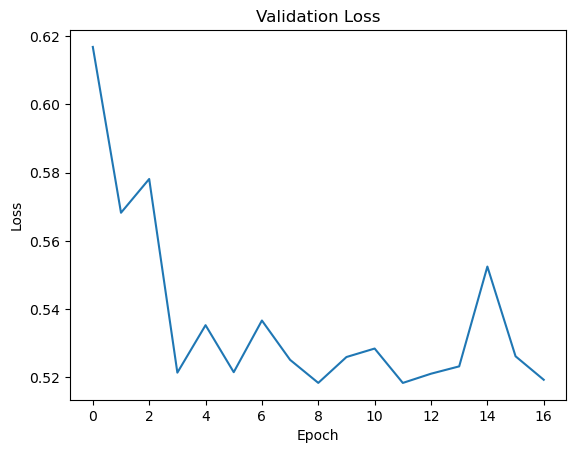

In [9]:
# Validation Loss Plot
plt.plot(history.history['val_loss'])
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()


In [10]:
# 6. Batch Normalization
bn_model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(256),
    BatchNormalization(),
    tf.keras.layers.ReLU(),
    Dense(10, activation='softmax')
])

bn_model.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

bn_model.fit(x_train, y_train, epochs=10)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8335 - loss: 0.4668
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8699 - loss: 0.3613
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8806 - loss: 0.3250
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8915 - loss: 0.2985
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8986 - loss: 0.2777
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9022 - loss: 0.2634
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9083 - loss: 0.2479
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9140 - loss: 0.2341
Epoch 9/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9191 - loss: 0.2212
Epoch 10/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9206 - loss: 0.2135


In [11]:
# Layer Normalization
ln_model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(256),
    LayerNormalization(),
    tf.keras.layers.ReLU(),
    Dense(10, activation='softmax')
])

ln_model.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

ln_model.fit(x_train, y_train, epochs=10)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8294 - loss: 0.4716
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8681 - loss: 0.3607
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8796 - loss: 0.3245
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8889 - loss: 0.2988
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8955 - loss: 0.2812
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9020 - loss: 0.2647
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9043 - loss: 0.2527
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9086 - loss: 0.2414
Epoch 9/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9125 - loss: 0.2318
Epoch 10/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9168 - loss: 0.2200


In [12]:

# Compare Accuracy
bn_acc = bn_model.evaluate(x_test, y_test, verbose=0)[1]
ln_acc = ln_model.evaluate(x_test, y_test, verbose=0)[1]

print("BatchNorm Accuracy:", bn_acc)
print("LayerNorm Accuracy:", ln_acc)

BatchNorm Accuracy: 0.8790000081062317
LayerNorm Accuracy: 0.8730000257492065


In [13]:
print("Batch Normalization Accuracy:", round(bn_acc*100, 2), "%")
print("Layer Normalization Accuracy:", round(ln_acc*100, 2), "%")

Batch Normalization Accuracy: 87.9 %
Layer Normalization Accuracy: 87.3 %


In [ ]:
# Final Accuracy
bn_acc = bn_model.evaluate(x_test, y_test, verbose=0)[1]
ln_acc = ln_model.evaluate(x_test, y_test, verbose=0)[1]

print("BatchNorm Accuracy:", round(bn_acc*100, 2), "%")
print("LayerNorm Accuracy:", round(ln_acc*100, 2), "%")

# Convergence Speed Comparison
plt.plot(history_bn.history['val_accuracy'], label='BatchNorm')
plt.plot(history_ln.history['val_accuracy'], label='LayerNorm')

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Convergence Speed Comparison')
plt.legend()
plt.show()